In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("modified_data.csv")

df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft
0,02-05-2014,313000.0,3,1.50,1340,7912,1.5,0,0,3,1340,0,1955,2005,18810 Densmore Ave N,Shoreline,WA 98133,233.58
1,02-05-2014,2384000.0,5,2.50,3650,9050,2.0,0,4,5,3370,280,1921,0,709 W Blaine St,Seattle,WA 98119,653.15
2,02-05-2014,342000.0,3,2.00,1930,11947,1.0,0,0,4,1930,0,1966,0,26206-26214 143rd Ave SE,Kent,WA 98042,177.20
3,02-05-2014,420000.0,3,2.25,2000,8030,1.0,0,0,4,1000,1000,1963,0,857 170th Pl NE,Bellevue,WA 98008,210.00
4,02-05-2014,550000.0,4,2.50,1940,10500,1.0,0,0,4,1140,800,1976,1992,9105 170th Ave NE,Redmond,WA 98052,283.51


### Exploratory Data Analysis (EDA)

In [2]:
df.shape

(4600, 18)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            4600 non-null   str    
 1   price           4600 non-null   float64
 2   bedrooms        4600 non-null   int64  
 3   bathrooms       4600 non-null   float64
 4   sqft_living     4600 non-null   int64  
 5   sqft_lot        4600 non-null   int64  
 6   floors          4600 non-null   float64
 7   waterfront      4600 non-null   int64  
 8   view            4600 non-null   int64  
 9   condition       4600 non-null   int64  
 10  sqft_above      4600 non-null   int64  
 11  sqft_basement   4600 non-null   int64  
 12  yr_built        4600 non-null   int64  
 13  yr_renovated    4600 non-null   int64  
 14  street          4600 non-null   str    
 15  city            4600 non-null   str    
 16  statezip        4600 non-null   str    
 17  price_per_sqft  4600 non-null   float64
dtyp

**Check missing values**

In [4]:
df.isnull().sum()

date              0
price             0
bedrooms          0
bathrooms         0
sqft_living       0
sqft_lot          0
floors            0
waterfront        0
view              0
condition         0
sqft_above        0
sqft_basement     0
yr_built          0
yr_renovated      0
street            0
city              0
statezip          0
price_per_sqft    0
dtype: int64

**Check duplicate records**

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.describe()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,price_per_sqft
count,4.600000e+03,4600.000000,4600.000000,4600.000000,4.600000e+03,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000,4600.000000
mean,5.519630e+05,3.400870,2.160815,2139.346957,1.485252e+04,1.512065,0.007174,0.240652,3.451739,1827.265435,312.081522,1970.786304,808.608261,265.876209
std,5.638347e+05,0.908848,0.783781,963.206916,3.588444e+04,0.538288,0.084404,0.778405,0.677230,862.168977,464.137228,29.731848,979.414536,357.503362
min,0.000000e+00,0.000000,0.000000,370.000000,6.380000e+02,1.000000,0.000000,0.000000,1.000000,370.000000,0.000000,1900.000000,0.000000,0.000000
25%,3.228750e+05,3.000000,1.750000,1460.000000,5.000750e+03,1.000000,0.000000,0.000000,3.000000,1190.000000,0.000000,1951.000000,0.000000,180.817500
50%,4.609435e+05,3.000000,2.250000,1980.000000,7.683000e+03,1.500000,0.000000,0.000000,3.000000,1590.000000,0.000000,1976.000000,0.000000,243.855000
75%,6.549625e+05,4.000000,2.500000,2620.000000,1.100125e+04,2.000000,0.000000,0.000000,4.000000,2300.000000,610.000000,1997.000000,1999.000000,314.840000
max,2.659000e+07,9.000000,8.000000,13540.000000,1.074218e+06,3.500000,1.000000,4.000000,5.000000,9410.000000,4820.000000,2014.000000,2014.000000,22533.900000


**Check zero house prices**

In [7]:
print("Zero-price houses:", (df["price"] == 0).sum())

df[df["price"] == 0].head()

Zero-price houses: 49


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,yr_built,yr_renovated,street,city,statezip,price_per_sqft
4354,05-05-2014,0.0,3,1.75,1490,10125,1.0,0,0,4,1490,0,1962,0,3911 S 328th St,Federal Way,WA 98001,0.0
4356,05-05-2014,0.0,4,2.75,2600,5390,1.0,0,0,4,1300,1300,1960,2001,2120 31st Ave W,Seattle,WA 98199,0.0
4357,05-05-2014,0.0,6,2.75,3200,9200,1.0,0,2,4,1600,1600,1953,1983,12271 Marine View Dr SW,Burien,WA 98146,0.0
4358,06-05-2014,0.0,5,3.50,3480,36615,2.0,0,0,4,2490,990,1983,0,21809 SE 38th Pl,Issaquah,WA 98075,0.0
4361,07-05-2014,0.0,5,1.50,1500,7112,1.0,0,0,5,760,740,1920,0,14901-14999 12th Ave SW,Burien,WA 98166,0.0


**Visualize house price distribution**

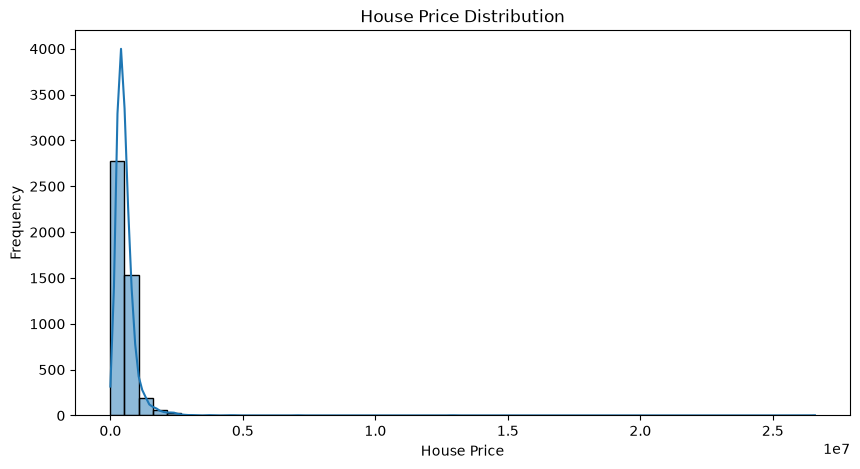

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(df["price"], bins=50, kde=True)

plt.title("House Price Distribution")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.show()

**Relationship between living area and price**

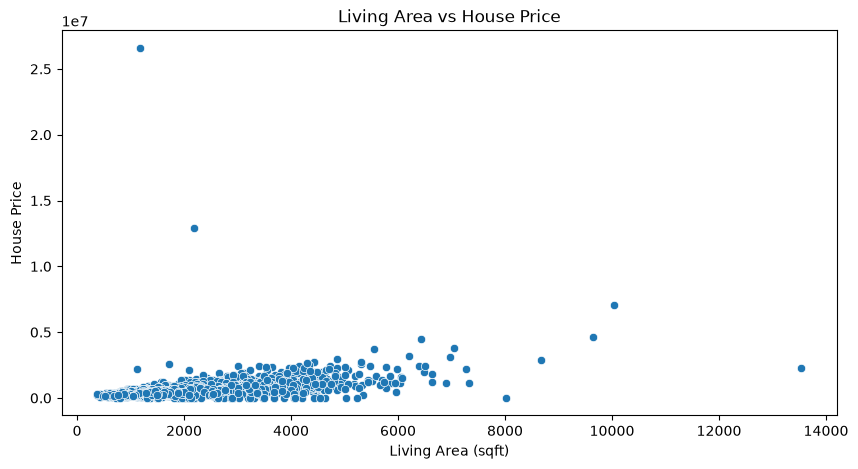

In [9]:
plt.figure(figsize=(10, 5))

sns.scatterplot(data=df, x="sqft_living", y="price")

plt.title("Living Area vs House Price")
plt.xlabel("Living Area (sqft)")
plt.ylabel("House Price")

plt.show()

### Data Preprocessing

**Create a clean dataset**

In [10]:
df_clean = df.copy()

print("Original shape:", df_clean.shape)

# Remove invalid target values
df_clean = df_clean[df_clean["price"] > 0].copy()

print("Shape after removing zero prices:", df_clean.shape)

Original shape: (4600, 18)
Shape after removing zero prices: (4551, 18)


**Separate features and target**

In [11]:
# Target variable
y = df_clean["price"]

# Remove target and potential data leakage
X = df_clean.drop(
    columns=["price", "price_per_sqft"],
    errors="ignore"
)

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Feature columns:")
print(X.columns.tolist())

Features shape: (4551, 16)
Target shape: (4551,)
Feature columns:
['date', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city', 'statezip']


In [12]:
X = X.drop(columns=["date", "street"], errors="ignore")

print(X.head())

   bedrooms  bathrooms  sqft_living  sqft_lot  floors  waterfront  view  \
0         3       1.50         1340      7912     1.5           0     0   
1         5       2.50         3650      9050     2.0           0     4   
2         3       2.00         1930     11947     1.0           0     0   
3         3       2.25         2000      8030     1.0           0     0   
4         4       2.50         1940     10500     1.0           0     0   

   condition  sqft_above  sqft_basement  yr_built  yr_renovated       city  \
0          3        1340              0      1955          2005  Shoreline   
1          5        3370            280      1921             0    Seattle   
2          4        1930              0      1966             0       Kent   
3          4        1000           1000      1963             0   Bellevue   
4          4        1140            800      1976          1992    Redmond   

   statezip  
0  WA 98133  
1  WA 98119  
2  WA 98042  
3  WA 98008  
4  WA 9805

**Split training and testing data**

In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3640, 14)
Testing data: (911, 14)


**Encode categorical columns and scale features**

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

categorical_cols = ["city", "statezip"]

numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_cols)
    ]
)

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (3640, 131)
Scaled testing shape: (911, 131)


**Scale the target variable**

In [15]:
import numpy as np

y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

print("First 5 scaled prices:")
print(y_train_scaled[:5])

First 5 scaled prices:
[-0.2644921  -0.51314299 -0.65508642 -0.29947816 -0.00709469]


### Implement SVM with All Four Kernels

**Import SVR and evaluation metrics**

In [16]:
from sklearn.svm import SVR
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

**Train all four SVR kernels**

In [17]:
# Define the four kernels
kernels = ["linear", "poly", "rbf", "sigmoid"]

# Store trained models
models = {}

# Store evaluation results
results = []

for kernel in kernels:

    print(f"Training {kernel.upper()} Kernel...")

    model = SVR(
        kernel=kernel,
        C=10,
        epsilon=0.1,
        gamma="scale"
    )

    # Train the model
    model.fit(X_train_scaled, y_train_scaled)

    # Predict test data
    y_pred_scaled = model.predict(X_test_scaled)

    # Convert predictions back to original prices
    y_pred = y_scaler.inverse_transform(
        y_pred_scaled.reshape(-1, 1)
    ).ravel()

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # Store model
    models[kernel] = model

    # Store results
    results.append({
        "Kernel": kernel,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    print(f"{kernel.upper()} completed!\n")

Training LINEAR Kernel...
LINEAR completed!

Training POLY Kernel...
POLY completed!

Training RBF Kernel...
RBF completed!

Training SIGMOID Kernel...
SIGMOID completed!



**Display the performance comparison**

In [18]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
)

display(results_df.round(4))

,Kernel,MAE,MSE,RMSE,R2 Score
0,linear,1.022661e+05,4.231513e+10,2.057064e+05,0.7156
2,rbf,1.146426e+05,6.252314e+10,2.500463e+05,0.5797
1,poly,1.408401e+05,2.518259e+11,5.018226e+05,-0.6927
3,sigmoid,1.033656e+08,7.696508e+16,2.774258e+08,-517340.3577


**Visualize R² scores**

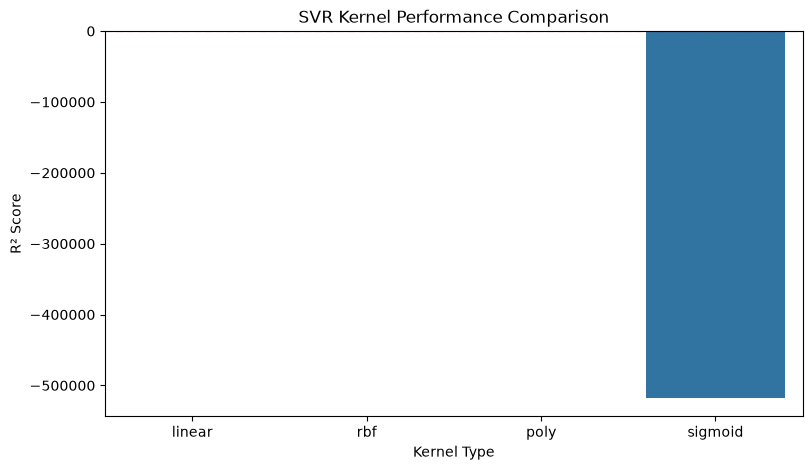

In [19]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Kernel",
    y="R2 Score"
)

plt.title("SVR Kernel Performance Comparison")
plt.xlabel("Kernel Type")
plt.ylabel("R² Score")

plt.axhline(y=0, color="red", linestyle="--")

plt.show()

**Identify the best kernel**

In [20]:
best_kernel = results_df.iloc[0]["Kernel"]
best_r2 = results_df.iloc[0]["R2 Score"]

print("Best Performing Kernel:", best_kernel.upper())
print("Best R2 Score:", round(best_r2, 4))

Best Performing Kernel: LINEAR
Best R2 Score: 0.7156


**Import GridSearchCV**

In [21]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR

**Define hyperparameter combinations**

In [24]:
param_grid = [
    {
        "kernel": ["linear"],
        "C": [1, 10],
        "epsilon": [0.1]
    },
    {
        "kernel": ["rbf"],
        "C": [1, 10],
        "gamma": ["scale"],
        "epsilon": [0.1]
    }
]

**Run GridSearchCV**

In [25]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR

grid_search = GridSearchCV(
    estimator=SVR(cache_size=500),
    param_grid=param_grid,
    cv=3,
    scoring="r2",
    n_jobs=1,
    verbose=2
)

grid_search.fit(X_train_scaled, y_train_scaled)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV R2 Score:")
print(grid_search.best_score_)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END ....................C=1, epsilon=0.1, kernel=linear; total time=   0.6s
[CV] END ....................C=1, epsilon=0.1, kernel=linear; total time=   0.6s
[CV] END ....................C=1, epsilon=0.1, kernel=linear; total time=   0.6s
[CV] END ...................C=10, epsilon=0.1, kernel=linear; total time=   4.7s
[CV] END ...................C=10, epsilon=0.1, kernel=linear; total time=   4.8s
[CV] END ...................C=10, epsilon=0.1, kernel=linear; total time=   4.8s
[CV] END ..........C=1, epsilon=0.1, gamma=scale, kernel=rbf; total time=   0.2s
[CV] END ..........C=1, epsilon=0.1, gamma=scale, kernel=rbf; total time=   0.1s
[CV] END ..........C=1, epsilon=0.1, gamma=scale, kernel=rbf; total time=   0.2s
[CV] END .........C=10, epsilon=0.1, gamma=scale, kernel=rbf; total time=   0.3s
[CV] END .........C=10, epsilon=0.1, gamma=scale, kernel=rbf; total time=   0.3s
[CV] END .........C=10, epsilon=0.1, gamma=scale,

**Evaluate your tuned model**

In [26]:
# Get the best model
best_model = grid_search.best_estimator_

# Predict house prices
y_pred_scaled = best_model.predict(X_test_scaled)

# Convert predictions to original price values
y_pred_tuned = y_scaler.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

# Calculate evaluation metrics
tuned_mae = mean_absolute_error(y_test, y_pred_tuned)
tuned_mse = mean_squared_error(y_test, y_pred_tuned)
tuned_rmse = np.sqrt(tuned_mse)
tuned_r2 = r2_score(y_test, y_pred_tuned)

print("Tuned SVR Model Results")
print("MAE:", tuned_mae)
print("MSE:", tuned_mse)
print("RMSE:", tuned_rmse)
print("R2 Score:", tuned_r2)

Tuned SVR Model Results
MAE: 102266.08391251497
MSE: 42315126494.59082
RMSE: 205706.40849178913
R2 Score: 0.7155675514373657


**Compare baseline and tuned models**

In [27]:
comparison = pd.DataFrame({
    "Model": ["Baseline Linear SVR", "Tuned Linear SVR"],
    "MAE": [
        results_df.loc[
            results_df["Kernel"] == "linear", "MAE"
        ].iloc[0],
        tuned_mae
    ],
    "RMSE": [
        results_df.loc[
            results_df["Kernel"] == "linear", "RMSE"
        ].iloc[0],
        tuned_rmse
    ],
    "R2 Score": [
        results_df.loc[
            results_df["Kernel"] == "linear", "R2 Score"
        ].iloc[0],
        tuned_r2
    ]
})

display(comparison.round(4))

,Model,MAE,RMSE,R2 Score
0,Baseline Linear SVR,102266.0839,205706.4085,0.7156
1,Tuned Linear SVR,102266.0839,205706.4085,0.7156


### Model Visualization

**Actual vs Predicted House Prices**

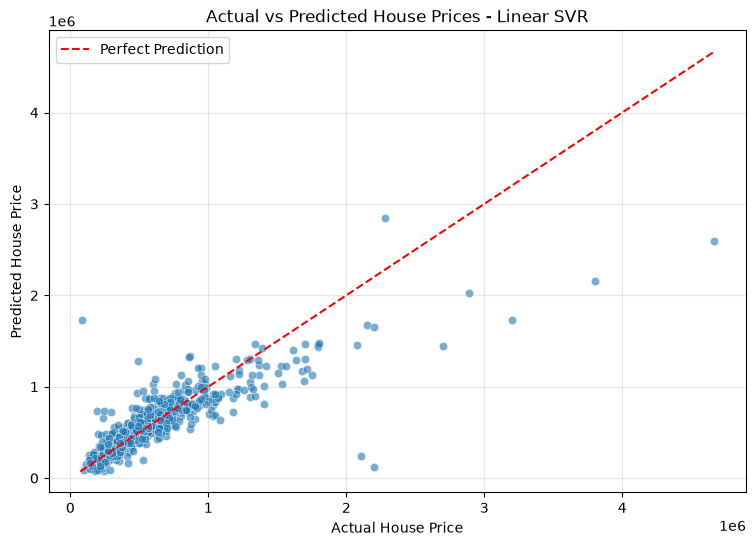

In [28]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_tuned,
    alpha=0.6
)

min_price = min(y_test.min(), y_pred_tuned.min())
max_price = max(y_test.max(), y_pred_tuned.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    "r--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted House Prices - Linear SVR")
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Residual Plot**

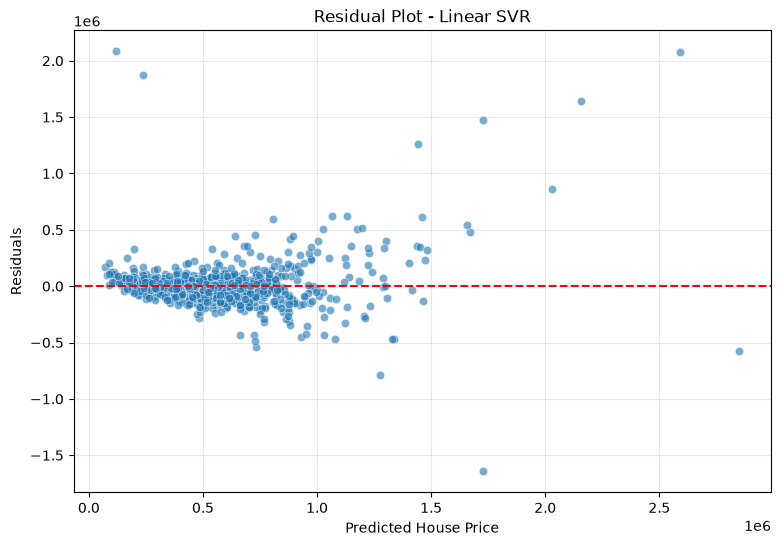

In [ ]:
residuals = y_test.to_numpy() - y_pred_tuned

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=y_pred_tuned,
    y=residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Residual Plot - Linear SVR")
plt.xlabel("Predicted House Price")
plt.ylabel("Residuals")
plt.grid(alpha=0.3)
plt.show()

**Compare all four kernels**

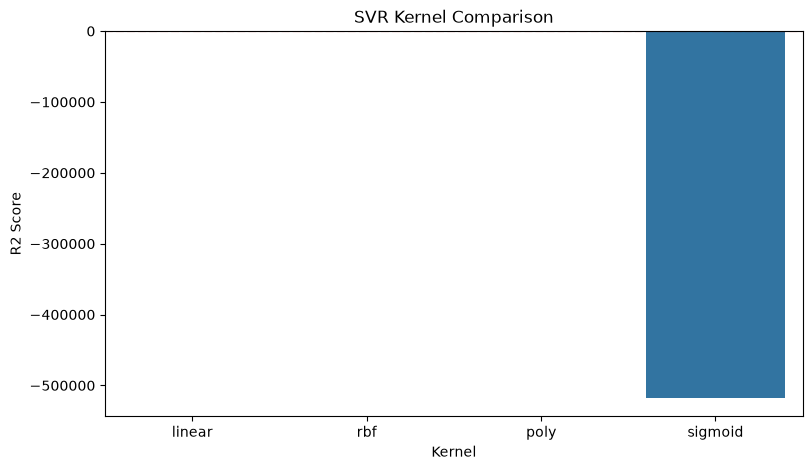

In [30]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Kernel",
    y="R2 Score"
)

plt.title("SVR Kernel Comparison")
plt.xlabel("Kernel")
plt.ylabel("R2 Score")
plt.axhline(0, color="red", linestyle="--")
plt.show()

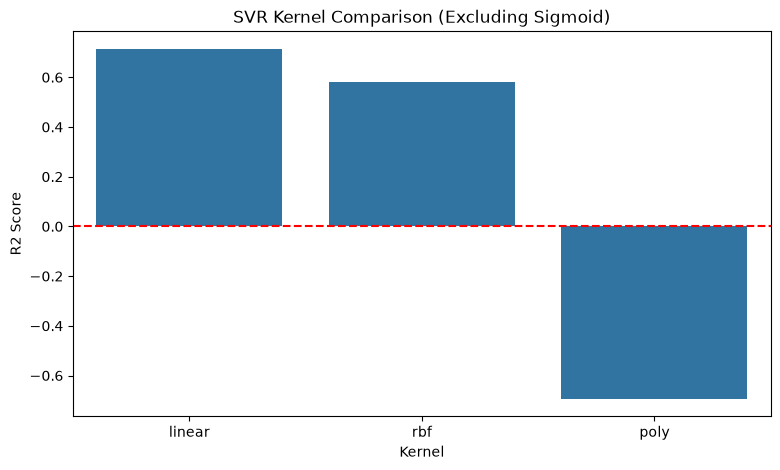

In [31]:
plot_df = results_df[
    results_df["Kernel"] != "sigmoid"
]

plt.figure(figsize=(9, 5))

sns.barplot(
    data=plot_df,
    x="Kernel",
    y="R2 Score"
)

plt.title("SVR Kernel Comparison (Excluding Sigmoid)")
plt.axhline(0, color="red", linestyle="--")
plt.show()

### Conclusion

In this project, I implemented Support Vector Regression (SVR) for House Price Prediction using four kernels: Linear, Polynomial, RBF, and Sigmoid.

I performed exploratory data analysis, data preprocessing, categorical encoding, feature scaling, and model evaluation.

Among the four kernels, **Linear SVR achieved the highest test R² score of 0.7156**, with an MAE of 102,266.08 and an RMSE of 205,706.41.

I also performed hyperparameter tuning using GridSearchCV with 3-fold cross-validation. The best configuration was Linear SVR with `C=10` and `epsilon=0.1`, achieving an average cross-validation R² score of 0.5148.

The tuned model produced the same test results as the baseline Linear SVR because both used identical hyperparameters.

I concluded that Linear SVR was the best-performing model among the tested configurations, although further feature engineering and broader hyperparameter tuning may improve performance.

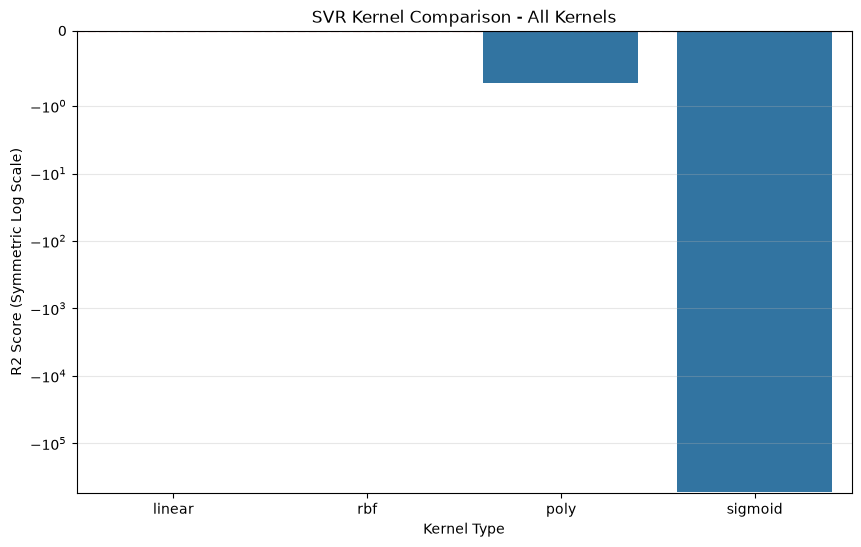

In [33]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Kernel",
    y="R2 Score"
)

plt.yscale("symlog", linthresh=1)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("SVR Kernel Comparison - All Kernels")
plt.xlabel("Kernel Type")
plt.ylabel("R2 Score (Symmetric Log Scale)")

plt.grid(axis="y", alpha=0.3)
plt.show()

### Actual vs Predicted House Prices

**Plot actual and predicted values**

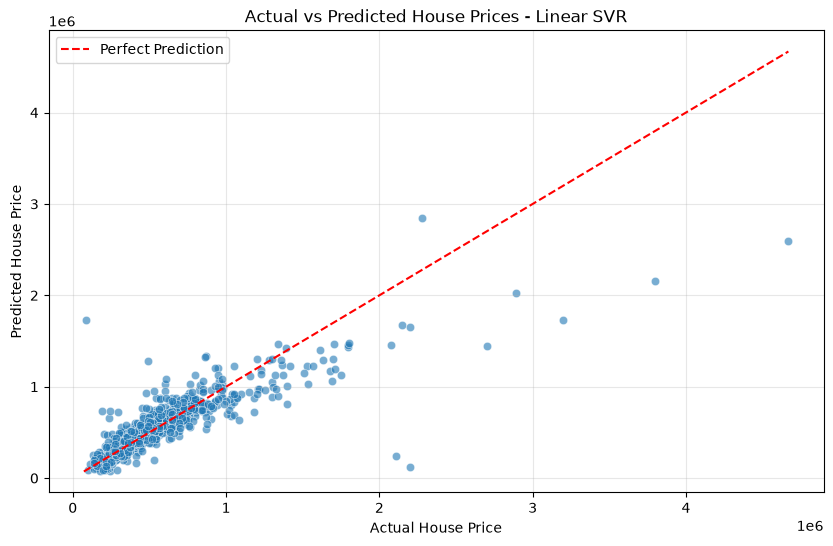

In [32]:
plt.figure(figsize=(10, 6))

# Actual vs Predicted
sns.scatterplot(
    x=y_test,
    y=y_pred_tuned,
    alpha=0.6
)

# Perfect prediction line
min_val = min(y_test.min(), y_pred_tuned.min())
max_val = max(y_test.max(), y_pred_tuned.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted House Prices - Linear SVR")
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Residual Analysis

**Calculate residuals**

In [34]:
residuals = y_test.to_numpy() - y_pred_tuned

print("First 10 residuals:")
print(residuals[:10])

First 10 residuals:
[  42771.27935181  -35239.25021122   42186.34321864   31436.15765263
  -18369.76742512    8259.20637152  -56526.77051193   71538.34449574
 -123168.40487844   61220.19387804]


**Plot residuals**

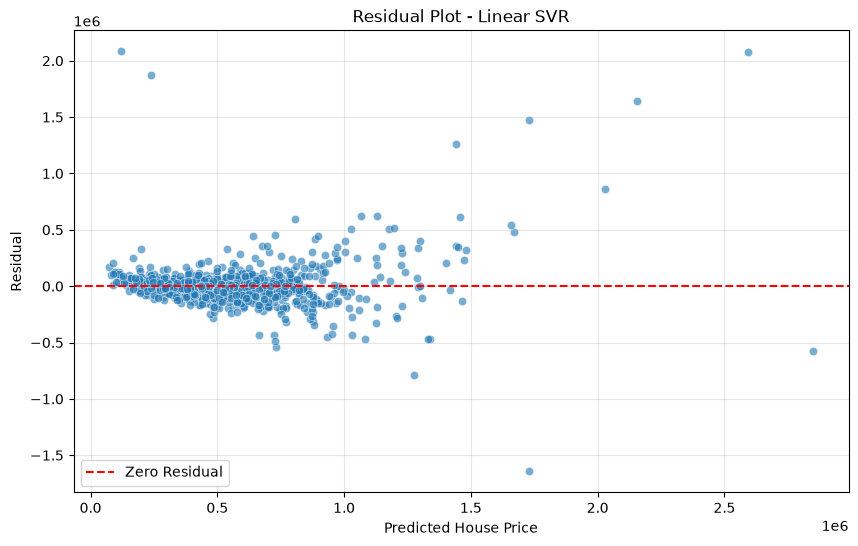

In [35]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=y_pred_tuned,
    y=residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero Residual"
)

plt.title("Residual Plot - Linear SVR")
plt.xlabel("Predicted House Price")
plt.ylabel("Residual")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Final Model Summary

**Final Model Summary**

In [36]:
final_results = pd.DataFrame({
    "Metric": [
        "Best Kernel",
        "C",
        "Epsilon",
        "MAE",
        "MSE",
        "RMSE",
        "R2 Score"
    ],
    "Value": [
        best_model.kernel,
        best_model.C,
        best_model.epsilon,
        round(tuned_mae, 4),
        round(tuned_mse, 4),
        round(tuned_rmse, 4),
        round(tuned_r2, 4)
    ]
})

display(final_results)

,Metric,Value
0,Best Kernel,linear
1,C,10
2,Epsilon,0.1
3,MAE,102266.0839
4,MSE,42315126494.590797
5,RMSE,205706.4085
6,R2 Score,0.7156


## Conclusion

In this project, I implemented Support Vector Regression (SVR) to predict house prices using Linear, Polynomial, RBF, and Sigmoid kernels.

I performed exploratory data analysis, data preprocessing, feature scaling, model training, and evaluation.

The Linear kernel achieved the best test R² score of **0.7156**, with an MAE of **102,266.08** and RMSE of **205,706.41**.

I performed hyperparameter tuning using GridSearchCV with 3-fold cross-validation. The best configuration was Linear SVR with `C=10` and `epsilon=0.1`.

The tuned model produced the same test results as the baseline because the selected hyperparameters were identical.

I also used Actual vs Predicted and Residual plots to visualize prediction performance and analyze model errors.

**Final outcome:** Linear SVR performed best among the tested kernel configurations for this House Price Prediction dataset.

## Final Conclusion

In this project, I implemented Support Vector Regression (SVR) for House Price Prediction using four kernels: Linear, Polynomial, RBF, and Sigmoid.

I performed exploratory data analysis, data preprocessing, feature scaling, model training, and evaluation using MAE, MSE, RMSE, and R².

Among the tested kernels, **Linear SVR achieved the best R² score of 0.7156**, with an MAE of 102,266.08 and RMSE of 205,706.41.

I performed hyperparameter tuning using GridSearchCV with 3-fold cross-validation. The best configuration was Linear SVR with C=10 and epsilon=0.1.

The Actual vs Predicted graph showed that the model performed reasonably well for many lower-priced houses but underestimated several expensive properties.

The residual plot revealed increasing prediction-error variability at higher predicted prices, indicating potential heteroscedasticity and sensitivity to outliers.

**Final Outcome:** Linear SVR was the best-performing kernel among the tested configurations, although further feature engineering and model optimization could improve its reliability.